# PS 8: NARMS tetracycline-resistance interim analysis

In [1]:
!pip install -q umap-learn openpyxl

## Upload your NARMS file


In [2]:
from google.colab import files
uploaded = files.upload()
DATA = list(uploaded)[0]
print('Uploaded:', DATA)

Saving CVM-NARMS-Cecal.xlsx to CVM-NARMS-Cecal.xlsx
Uploaded: CVM-NARMS-Cecal.xlsx


In [3]:
%%writefile ps8_narms.py
"""PS 8 interim analysis: tetracycline resistance in food-animal E. coli (FDA NARMS cecal data).

"""
from __future__ import annotations

import argparse
import hashlib
import json
import platform
import re
import sys
import time
import warnings
from datetime import datetime, timezone
from importlib import metadata
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import trustworthiness
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TRAIN_LAST_YEAR = 2019          # proposal: train 2013-2019, test 2020 onward
POLICY_YEAR = 2017              # FDA GFI #213 full implementation (Jan 2017)
MAX_MISSING = 0.30              # proposal: keep other drugs with <= 30% missing
TET_MIC_BREAKPOINT_R = 16.0     # used only if the file has MICs but no R/S column for TET
SOURCE_URL = "https://www.fda.gov/media/93351/download?attachment"
SOURCE_NAME = "FDA NARMS Bacterial Isolate Level Data - Food Producing Animals - USDA/FSIS (cecal, 2013-present)"

# Set any of these to the exact column name if auto-detection picks the wrong one.
COLUMN_OVERRIDES: dict[str, str | None] = {
    "year": None, "organism": None, "animal": None, "state": None, "tetracycline": None,
}

# Tetracycline-class drugs are excluded from features to prevent label leakage.
TET_CLASS = re.compile(r"^(tet|tetracycline|doxy|doxycycline|mino|minocycline|tgc|tigecycline)\b", re.I)

CENSUS_REGION = {
    **{s: "Northeast" for s in "CT ME MA NH RI VT NJ NY PA".split()},
    **{s: "Midwest" for s in "IL IN MI OH WI IA KS MN MO NE ND SD".split()},
    **{s: "South" for s in "DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX".split()},
    **{s: "West" for s in "AZ CO ID MT NV NM UT WY AK CA HI OR WA".split()},
}
STATE_NAMES = {
    "alabama": "AL", "alaska": "AK", "arizona": "AZ", "arkansas": "AR", "california": "CA", "colorado": "CO",
    "connecticut": "CT", "delaware": "DE", "district of columbia": "DC", "florida": "FL", "georgia": "GA",
    "hawaii": "HI", "idaho": "ID", "illinois": "IL", "indiana": "IN", "iowa": "IA", "kansas": "KS",
    "kentucky": "KY", "louisiana": "LA", "maine": "ME", "maryland": "MD", "massachusetts": "MA",
    "michigan": "MI", "minnesota": "MN", "mississippi": "MS", "missouri": "MO", "montana": "MT",
    "nebraska": "NE", "nevada": "NV", "new hampshire": "NH", "new jersey": "NJ", "new mexico": "NM",
    "new york": "NY", "north carolina": "NC", "north dakota": "ND", "ohio": "OH", "oklahoma": "OK",
    "oregon": "OR", "pennsylvania": "PA", "rhode island": "RI", "south carolina": "SC",
    "south dakota": "SD", "tennessee": "TN", "texas": "TX", "utah": "UT", "vermont": "VT",
    "virginia": "VA", "washington": "WA", "west virginia": "WV", "wisconsin": "WI", "wyoming": "WY",
}


# --------------------------------------------------------------------------- loading
def load_table(path: Path) -> pd.DataFrame:
    if path.suffix.lower() in {".xlsx", ".xls"}:
        df = pd.read_excel(path)
    else:
        try:
            df = pd.read_csv(path, low_memory=False)
        except UnicodeDecodeError:
            df = pd.read_csv(path, low_memory=False, encoding="latin-1")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def norm_rs(series: pd.Series) -> pd.Series:
    """Map interpretation strings to R/S/I; anything else becomes NaN."""
    s = series.astype("string").str.strip().str.upper()
    mapping = {"R": "R", "RESISTANT": "R", "S": "S", "SUSCEPTIBLE": "S", "SUSC": "S",
               "I": "I", "INTERMEDIATE": "I", "INT": "I"}
    return s.map(mapping)


def is_rs_column(series: pd.Series) -> bool:
    vals = series.dropna()
    if len(vals) < 20:
        return False
    return norm_rs(vals).notna().mean() > 0.95 and norm_rs(vals).nunique() >= 2


def parse_mic(series: pd.Series) -> pd.Series:
    s = series.astype("string").str.replace(r"[<>=≤≥\s]", "", regex=True)
    return pd.to_numeric(s, errors="coerce")


def find_col(df: pd.DataFrame, key: str, patterns: list[str], exclude: list[str] = ()) -> str | None:
    if COLUMN_OVERRIDES.get(key):
        return COLUMN_OVERRIDES[key]
    for pat in patterns:
        for c in df.columns:
            if re.search(pat, c, re.I) and not any(re.search(e, c, re.I) for e in exclude):
                return c
    return None


def drug_name(col: str) -> str:
    return re.sub(r"[\s_\-]*(rslt|result|interp(retation)?|sir|r/s|concl(usion)?)$", "", col, flags=re.I).strip()


def detect(df: pd.DataFrame) -> dict:
    cols = {
        "year": find_col(df, "year", [r"^year$", r"data.?year", r"collection.?year", r"\byear\b"]),
        "organism": find_col(df, "organism", [r"^genus$", r"genus", r"organism", r"^species$", r"bacteri"],
                             exclude=[r"host", r"source", r"animal"]),
        "animal": find_col(df, "animal", [r"host.?species", r"source.?species", r"animal", r"^host",
                                          r"commodity", r"slaughter.?class", r"^source$"]),
        "state": find_col(df, "state", [r"^state$", r"state"]),
    }
    rs_cols = [c for c in df.columns if c not in cols.values() and is_rs_column(df[c])]
    drugs = {drug_name(c): c for c in rs_cols}
    tet = COLUMN_OVERRIDES.get("tetracycline") or next(
        (c for d, c in drugs.items() if re.fullmatch(r"(tet|tetracycline)", d, re.I)), None)
    tet_mic = None
    if tet is None:  # fall back to a MIC column + fixed breakpoint
        tet_mic = next((c for c in df.columns if re.fullmatch(r"(tet|tetracycline)([\s_]*mic)?", c, re.I)), None)
    mic_drugs = {}
    if not drugs:  # file has MIC values only: use log2(MIC) for the other drugs
        for c in df.columns:
            if c in cols.values() or not re.fullmatch(r"[A-Za-z]{3,4}([\s_]*mic)?", c, re.I):
                continue
            vals = df[c].dropna()
            if len(vals) >= 20 and parse_mic(vals).notna().mean() > 0.95:
                mic_drugs[re.sub(r"[\s_]*mic$", "", c, flags=re.I)] = c
    cols.update({"drugs": drugs, "mic_drugs": mic_drugs, "tetracycline": tet, "tetracycline_mic": tet_mic})
    return cols


def inspect(df: pd.DataFrame, path: Path) -> None:
    print(f"{path}: {len(df):,} rows x {df.shape[1]} columns\n")
    for c in df.columns:
        vals = df[c].dropna().astype(str).unique()[:6]
        print(f"  {c!r:38s} missing={df[c].isna().mean():5.1%}  e.g. {list(vals)}")
    d = detect(df)
    print("\nAuto-detected:")
    for k in ["year", "organism", "animal", "state", "tetracycline", "tetracycline_mic"]:
        print(f"  {k:18s} -> {d[k]!r}")
    print(f"  R/S drug columns  -> {len(d['drugs'])}: {list(d['drugs'])}")
    if d["mic_drugs"]:
        print(f"  MIC drug columns  -> {len(d['mic_drugs'])}: {list(d['mic_drugs'])} (used as log2 MIC)")
    print("\nIf anything is wrong, set COLUMN_OVERRIDES at the top of the script.")


# --------------------------------------------------------------------------- dataset
def to_region(state) -> str:
    if pd.isna(state):
        return "Unknown"
    s = str(state).strip()
    code = s.upper() if len(s) == 2 else STATE_NAMES.get(s.lower(), "")
    return CENSUS_REGION.get(code, "Unknown")


def build_dataset(raw: pd.DataFrame, cols: dict) -> tuple[pd.DataFrame, list[str], dict]:
    notes: dict = {"rows_raw": int(len(raw))}
    df = raw.copy()
    org = cols["organism"]
    if org is None:
        raise SystemExit("Could not find an organism/genus column; set COLUMN_OVERRIDES['organism'].")
    is_ecoli = df[org].astype("string").str.contains(r"escherichia|e\.?\s*coli|^ec$", case=False, regex=True)
    if "species" not in org.lower():
        sp = next((c for c in df.columns if re.fullmatch(r"species", c, re.I)), None)
        if sp is not None and df[org].astype("string").str.contains("escherichia", case=False).any():
            is_ecoli &= df[sp].astype("string").str.contains("coli", case=False) | df[sp].isna()
    df = df[is_ecoli.fillna(False)].copy()
    notes["rows_ecoli"] = int(len(df))
    if df.empty:
        raise SystemExit(f"No E. coli rows found using column {org!r}. Check --inspect output.")

    out = pd.DataFrame(index=df.index)
    out["year"] = pd.to_numeric(df[cols["year"]], errors="coerce")
    out["animal"] = df[cols["animal"]].astype("string").str.strip().str.title() if cols["animal"] else "Unknown"
    out["region"] = df[cols["state"]].map(to_region) if cols["state"] else "Unknown"

    if cols["tetracycline"]:
        tet = norm_rs(df[cols["tetracycline"]])
        notes["label_source"] = f"interpretation column {cols['tetracycline']!r}"
    elif cols["tetracycline_mic"]:
        mic = parse_mic(df[cols["tetracycline_mic"]])
        tet = pd.Series(np.where(mic >= TET_MIC_BREAKPOINT_R, "R", np.where(mic <= 4, "S", "I")), index=df.index)
        tet[mic.isna()] = pd.NA
        notes["label_source"] = f"MIC column {cols['tetracycline_mic']!r}, R >= {TET_MIC_BREAKPOINT_R:g} ug/mL"
    else:
        raise SystemExit("No tetracycline column found; set COLUMN_OVERRIDES['tetracycline'].")
    notes["tet_intermediate_excluded"] = int((tet == "I").sum())
    notes["tet_missing_excluded"] = int(tet.isna().sum())
    out["y"] = tet.map({"R": 1, "S": 0})

    feature_drugs = []
    for d, c in cols["drugs"].items():
        if c == cols["tetracycline"] or TET_CLASS.match(d):
            continue
        r = norm_rs(df[c])
        miss = r.isna().mean()
        if miss <= MAX_MISSING:
            out[f"R_{d}"] = r.map({"R": 1.0, "I": 0.0, "S": 0.0})   # I counted as not resistant
            feature_drugs.append(f"R_{d}")
    for d, c in cols["mic_drugs"].items():
        if c == cols["tetracycline_mic"] or TET_CLASS.match(d):
            continue
        mic = parse_mic(df[c])
        if mic.isna().mean() <= MAX_MISSING:
            out[f"L_{d}"] = np.log2(mic.clip(lower=1e-3))
            feature_drugs.append(f"L_{d}")
    if cols["mic_drugs"]:
        notes["feature_encoding"] = "log2(MIC) per drug (file has no R/S interpretation columns)"
    else:
        notes["feature_encoding"] = "binary resistant indicator per drug (I counted as not resistant)"
    all_drugs = list(cols["drugs"]) + list(cols["mic_drugs"])
    notes["drugs_kept"] = [f[2:] for f in feature_drugs]
    notes["drugs_dropped_missing_or_tet_class"] = [d for d in all_drugs if d not in notes["drugs_kept"]]

    out = out[out.y.notna() & out.year.notna()].copy()
    out["y"] = out.y.astype(int)
    out["year"] = out.year.astype(int)
    notes["rows_modelled"] = int(len(out))
    return out, feature_drugs, notes


# --------------------------------------------------------------------------- figures
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centre - half, centre + half


def fig_prevalence(df: pd.DataFrame, out: Path) -> pd.DataFrame:
    rows = []
    for (animal, year), g in df.groupby(["animal", "year"]):
        k, n = int(g.y.sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append({"animal": animal, "year": year, "n": n, "resistant": k,
                     "prevalence": k / n, "ci95_low": lo, "ci95_high": hi})
    t = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for animal, g in t.groupby("animal"):
        g = g[g.n >= 10]
        if g.empty:
            continue
        ax.plot(g.year, g.prevalence, marker="o", ms=4, label=f"{animal}")
        ax.fill_between(g.year, g.ci95_low, g.ci95_high, alpha=0.15)
    ax.axvline(POLICY_YEAR - 0.5, color="#555", ls="--", lw=1)
    ax.text(POLICY_YEAR - 0.4, 0.02, "FDA GFI #213\n(Jan 2017)", fontsize=8, color="#555")
    ax.axvspan(TRAIN_LAST_YEAR + 0.5, t.year.max() + 0.5, color="#999", alpha=0.08)
    ax.text(TRAIN_LAST_YEAR + 0.6, 0.95, "temporal test", fontsize=8, color="#555", va="top")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Collection year")
    ax.set_ylabel("Tetracycline-resistant share")
    ax.set_title("E. coli tetracycline resistance by animal source (95% Wilson CI; years with n >= 10)")
    ax.legend(frameon=False, fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out, dpi=160)
    plt.close(fig)
    return t


def fig_umap(df: pd.DataFrame, drugs: list[str], out: Path, nn_grid, md_grid, max_points: int) -> pd.DataFrame:
    import umap

    sub = df.sample(n=min(max_points, len(df)), random_state=SEED)
    X = sub[drugs].fillna(sub[drugs].mode().iloc[0]).to_numpy(dtype=float)
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), size=min(1500, len(X)), replace=False)
    colors = np.where(sub.y.to_numpy() == 1, "#C0392B", "#2E86C1")
    fig, axes = plt.subplots(len(nn_grid), len(md_grid), figsize=(3.4 * len(md_grid), 3.2 * len(nn_grid)),
                             squeeze=False)
    rows = []
    jitter = np.random.default_rng(SEED).normal(scale=1e-3, size=X.shape)  # breaks exact-duplicate ties
    for i, nn in enumerate(nn_grid):
        for j, md in enumerate(md_grid):
            t0 = time.time()
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                Y = umap.UMAP(n_neighbors=nn, min_dist=md, metric="euclidean",
                              random_state=SEED).fit_transform(X + jitter)
            tw = trustworthiness(X[idx] + jitter[idx], Y[idx], n_neighbors=10)
            rows.append({"n_neighbors": nn, "min_dist": md, "trustworthiness@10": round(float(tw), 4),
                         "fit_seconds": round(time.time() - t0, 1)})
            ax = axes[i, j]
            ax.scatter(Y[:, 0], Y[:, 1], s=3, c=colors, alpha=0.5, linewidths=0)
            ax.set_title(f"n_neighbors={nn}, min_dist={md}\ntrustworthiness={tw:.3f}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
            print(f"  UMAP nn={nn:>3} md={md:<4} T={tw:.3f}")
    handles = [plt.Line2D([], [], marker="o", ls="", color="#C0392B", label="tetracycline R"),
               plt.Line2D([], [], marker="o", ls="", color="#2E86C1", label="tetracycline S")]
    fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
    fig.suptitle(f"UMAP sweep: {len(X):,} isolate resistance profiles\n"
                 f"({len(drugs)} non-tetracycline drugs, random_state={SEED})", fontsize=11)
    fig.tight_layout(rect=(0, 0.06, 1, 0.95))
    fig.savefig(out, dpi=160)
    plt.close(fig)
    return pd.DataFrame(rows)


def fig_coresistance(df: pd.DataFrame, drugs: list[str], out: Path) -> pd.DataFrame:
    cols = ["y"] + drugs
    corr = df[cols].astype(float).corr(min_periods=30)  # Pearson on 0/1 = phi coefficient
    corr = corr.rename(index={"y": "TET"}, columns={"y": "TET"})
    corr.index = [re.sub(r"^(R|L)_", "", c) for c in corr.index]
    corr.columns = corr.index
    fig, ax = plt.subplots(figsize=(0.45 * len(cols) + 2.5, 0.45 * len(cols) + 1.8))
    im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
    for a in range(len(corr)):
        for b in range(len(corr)):
            v = corr.iat[a, b]
            if pd.notna(v) and a != b:
                ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(v) > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, label="phi coefficient")
    ax.set_title("Co-resistance among drugs (E. coli isolates)")
    fig.tight_layout()
    fig.savefig(out, dpi=160)
    plt.close(fig)
    return corr


def fig_missingness(raw_e: pd.DataFrame, cols: dict, out: Path) -> None:
    ycol = cols["year"]
    drugs = cols["drugs"] or cols["mic_drugs"]
    if not drugs:
        return
    tested = pd.DataFrame({d: raw_e[c].notna() for d, c in drugs.items()})
    tested["year"] = pd.to_numeric(raw_e[ycol], errors="coerce")
    m = tested.groupby("year").mean().T * 100
    fig, ax = plt.subplots(figsize=(0.5 * m.shape[1] + 3, 0.32 * m.shape[0] + 1.8))
    im = ax.imshow(m.to_numpy(), cmap="Greens", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(m.shape[1]), [str(int(y)) for y in m.columns], rotation=90, fontsize=8)
    ax.set_yticks(range(m.shape[0]), m.index, fontsize=8)
    fig.colorbar(im, ax=ax, label="% isolates tested")
    ax.set_title("Drug-panel coverage by year (E. coli)")
    fig.tight_layout()
    fig.savefig(out, dpi=160)
    plt.close(fig)


# --------------------------------------------------------------------------- models
def make_model(kind: str, drugs: list[str]):
    cat = ["animal", "region"]
    if kind == "majority":
        return DummyClassifier(strategy="most_frequent")
    num = ["year"] + (drugs if kind == "lr_A" else [])
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("scale", StandardScaler())]),
         num),
    ])
    return Pipeline([("pre", pre),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))])


def score(model, X, y) -> dict:
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else pred
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y, pred),
        "precision_R": precision_score(y, pred, zero_division=0),
        "recall_R": recall_score(y, pred, zero_division=0),
        "f1_R": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba) if len(np.unique(y)) == 2 else float("nan"),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }


def run_baselines(df: pd.DataFrame, drugs: list[str]) -> tuple[pd.DataFrame, dict]:
    feats = ["animal", "region", "year"] + drugs
    rows, info = [], {}
    train = df[df.year <= TRAIN_LAST_YEAR]
    test = df[df.year > TRAIN_LAST_YEAR]
    info["temporal_train_n"], info["temporal_test_n"] = int(len(train)), int(len(test))
    splits = {}
    if len(test) >= 30 and train.y.nunique() == 2:
        splits[f"temporal (train <= {TRAIN_LAST_YEAR}, test >= {TRAIN_LAST_YEAR + 1})"] = (train, test)
    else:
        info["temporal_note"] = "too few post-2019 isolates for a temporal test; only the random split is reported"
    tr, te = train_test_split(df, test_size=0.2, stratify=df.y, random_state=SEED)
    splits["random stratified 80/20"] = (tr, te)

    for split_name, (tr, te) in splits.items():
        for kind, label in [("majority", "Majority class (naive baseline)"),
                            ("lr_B", "Logistic regression, Scenario B (animal, year, region)"),
                            ("lr_A", "Logistic regression, Scenario A (+ other drugs)")]:
            m = make_model(kind, drugs).fit(tr[feats], tr.y)
            r = {"split": split_name, "model": label, "n_train": len(tr), "n_test": len(te)}
            r.update(score(m, te[feats], te.y))
            if kind != "majority":
                cv = cross_val_score(make_model(kind, drugs), tr[feats], tr.y, scoring="roc_auc",
                                     cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
                r["cv_auc_mean"], r["cv_auc_sd"] = cv.mean(), cv.std()
            rows.append(r)
            print(f"  {split_name[:8]:8s} {label[:45]:45s} recall_R={r['recall_R']:.3f} AUC={r['roc_auc']:.3f}")
    return pd.DataFrame(rows), info


# --------------------------------------------------------------------------- manifest
def versions() -> pd.DataFrame:
    rows = [{"component": "python", "version": platform.python_version()},
            {"component": "os", "version": f"{platform.system()} {platform.release()}"}]
    for pkg in ["numpy", "pandas", "scikit-learn", "matplotlib", "umap-learn", "openpyxl"]:
        try:
            rows.append({"component": pkg, "version": metadata.version(pkg)})
        except metadata.PackageNotFoundError:
            rows.append({"component": pkg, "version": "not installed"})
    return pd.DataFrame(rows)


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data", required=True, help="NARMS cecal file you downloaded (.xlsx or .csv)")
    ap.add_argument("--out", default="interim")
    ap.add_argument("--inspect", action="store_true", help="print columns and detected roles, then stop")
    ap.add_argument("--quick", action="store_true", help="2x2 UMAP grid on fewer points")
    args = ap.parse_args()
    path, out = Path(args.data), Path(args.out)
    out.mkdir(parents=True, exist_ok=True)

    print(f"[1/6] loading {path}")
    raw_bytes = path.read_bytes()
    raw = load_table(path)
    if args.inspect:
        inspect(raw, path)
        return
    cols = detect(raw)
    print("  detected:", {k: v for k, v in cols.items() if k not in ("drugs", "mic_drugs")}, f"+ {len(cols['drugs'])} drug columns")

    print("[2/6] building dataset")
    df, drugs, notes = build_dataset(raw, cols)
    raw_e = raw.loc[raw.index.isin(df.index)]
    print(f"  {notes['rows_modelled']:,} E. coli isolates with a tetracycline label; {len(drugs)} feature drugs")

    pd.DataFrame([{
        "source": SOURCE_NAME, "whitelist_id / license_class": "public_domain (U.S. federal government data)",
        "url": SOURCE_URL, "file": path.name, "size_bytes": len(raw_bytes),
        "rows_raw": notes["rows_raw"], "rows_ecoli": notes["rows_ecoli"], "rows_modelled": notes["rows_modelled"],
        "years": f"{df.year.min()}-{df.year.max()}",
        "ingest_method": "manual HTTPS download from FDA NARMS Integrated Reports/Summaries; raw file kept unmodified; "
                         "pandas load; E. coli filter",
        "sha256": hashlib.sha256(raw_bytes).hexdigest(),
        "loaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }]).to_csv(out / "provenance.csv", index=False)

    print("[3/6] figures")
    prev = fig_prevalence(df, out / "fig1_prevalence_drift.png")
    prev.to_csv(out / "prevalence_by_year.csv", index=False)
    if len(drugs) >= 2:
        nn, md = ([5, 30], [0.0, 0.5]) if args.quick else ([5, 15, 50], [0.0, 0.1, 0.5])
        sweep = fig_umap(df, drugs, out / "fig2_umap_sweep.png", nn, md, 3000 if args.quick else 8000)
        sweep.to_csv(out / "umap_sweep.csv", index=False)
        corr = fig_coresistance(df, drugs, out / "fig3_coresistance.png")
        corr.to_csv(out / "coresistance_phi.csv")
    else:
        sweep = pd.DataFrame()
        print("  fewer than 2 feature drugs; UMAP and co-resistance figures skipped")
    fig_missingness(raw_e, cols, out / "fig4_missingness.png")

    print("[4/6] baselines")
    res, split_info = run_baselines(df, drugs)
    res.round(4).to_csv(out / "baselines.csv", index=False)

    print("[5/6] manifest")
    ver = versions()
    ver.to_csv(out / "versions.csv", index=False)

    period = df.assign(period=np.where(df.year < POLICY_YEAR, f"control (<{POLICY_YEAR})",
                                       f"treatment (>={POLICY_YEAR})"))
    by_period = period.groupby(["animal", "period"]).y.agg(["count", "mean"]).round(4)

    metrics = {**notes, **split_info,
               "class_balance_resistant_share": round(float(df.y.mean()), 4),
               "isolates_by_animal": df.animal.value_counts().to_dict(),
               "isolates_by_year": {int(k): int(v) for k, v in df.year.value_counts().sort_index().items()}}
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))

    print("[6/6] summary")
    pd.set_option("display.width", 200)
    lines = [
        "PS 8 SUMMARY - all metrics are advisory (INV-12)",
        f"Source: {SOURCE_NAME}",
        f"Rows: raw {notes['rows_raw']:,} -> E. coli {notes['rows_ecoli']:,} -> modelled {notes['rows_modelled']:,} "
        f"(intermediate excluded: {notes['tet_intermediate_excluded']}, missing label: {notes['tet_missing_excluded']})",
        f"Label: {notes['label_source']}; resistant share = {df.y.mean():.3f}",
        f"Feature drugs kept (<= {MAX_MISSING:.0%} missing, tetracycline class excluded): {notes['drugs_kept']}",
        f"Feature encoding: {notes['feature_encoding']}",
        f"Drugs dropped: {notes['drugs_dropped_missing_or_tet_class']}",
        f"Temporal split: train n={split_info['temporal_train_n']}, test n={split_info['temporal_test_n']}"
        + (f"  NOTE: {split_info['temporal_note']}" if "temporal_note" in split_info else ""),
        "", "Isolates by animal:", df.animal.value_counts().to_string(),
        "", f"Resistance by period (FDA GFI #213, {POLICY_YEAR}):", by_period.to_string(),
        "", "UMAP sweep:", sweep.to_string(index=False) if len(sweep) else "(skipped)",
        "", "Baselines (test set):",
        res[["split", "model", "n_train", "n_test", "accuracy", "precision_R", "recall_R", "f1_R", "roc_auc"]
            + [c for c in ["cv_auc_mean", "cv_auc_sd"] if c in res]].round(3).to_string(index=False),
        "", "Component versions:", ver.to_string(index=False),
    ]
    summary = "\n".join(lines)
    (out / "summary.txt").write_text(summary)
    print("\n" + summary + f"\n\nOutputs written to {out.resolve()}")


if __name__ == "__main__":
    sys.exit(main())


Writing ps8_narms.py


## Check the detected columns


In [4]:
!python ps8_narms.py --data "$DATA" --inspect

[1/6] loading CVM-NARMS-Cecal.xlsx
CVM-NARMS-Cecal.xlsx: 74,701 rows x 201 columns

  'SAMPLE_ID'                            missing= 0.0%  e.g. ['210016056.0', '210017320.0', '210017285.0', '210017296.0', '210018604.0', '210019980.0']
  'GENUS_NAME'                           missing= 0.0%  e.g. ['Campylobacter', 'Enterococcus', 'Salmonella', 'Escherichia', 'Pseudomonas', 'Proteus']
  'GROWTH'                               missing= 0.0%  e.g. ['YES', 'NO']
  'SPECIES'                              missing=14.0%  e.g. ['jejuni', 'other', 'coli', 'enterica', 'faecalis', 'faecium']
  'SEROTYPE'                             missing=81.2%  e.g. ['Senftenberg', 'Muenster', 'Typhimurium', 'Muenchen', 'Rissen', 'Anatum']
  'ISOLATE_ID'                           missing=14.7%  e.g. ['210016056.0', '210017320.0', '210017285.0', '210017296.0', '210018604.0', '210019980.0']
  'RECEIVED_DATE'                        missing=92.2%  e.g. ['10/18/2013', '9/26/2013', '7/25/2013', '7/9/2013', '8/1/2013', '

## Run the full analysis

In [5]:
!python ps8_narms.py --data "$DATA"

[1/6] loading CVM-NARMS-Cecal.xlsx
  detected: {'year': 'Year', 'organism': 'GENUS_NAME', 'animal': 'HOST_SPECIES', 'state': 'STATE', 'tetracycline': 'TET SIR', 'tetracycline_mic': None} + 36 drug columns
[2/6] building dataset
  17,865 E. coli isolates with a tetracycline label; 14 feature drugs
[3/6] figures
I0000 00:00:1794076954.322436    6432 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
  UMAP nn=  5 md=0.0  T=0.834
  UMAP nn=  5 md=0.1  T=0.839
  UMAP nn=  5 md=0.5  T=0.806
  UMAP nn= 15 md=0.0  T=0.838
  UMAP nn= 15 md=0.1  T=0.832
  UMAP nn= 15 md=0.5  T=0.809
  UMAP nn= 50 md=0.0  T=0.838
  UMAP nn= 50 md=0.1  T=0.833
  UMAP nn= 50 md=0.5  T=0.815
[4/6] baselines
  temporal Majority class (naive baseline)               recall_R=0.000 AUC=0.500
  temporal Logist

## View the figures

interim/fig1_prevalence_drift.png


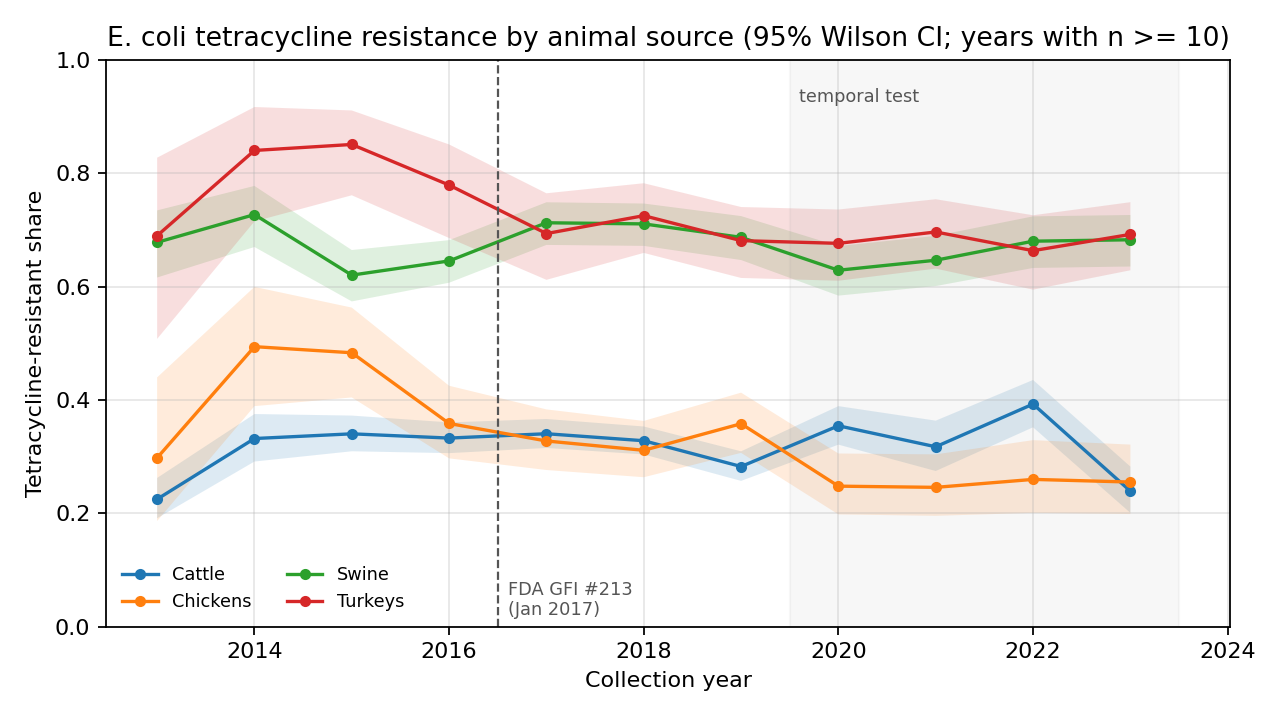

interim/fig2_umap_sweep.png


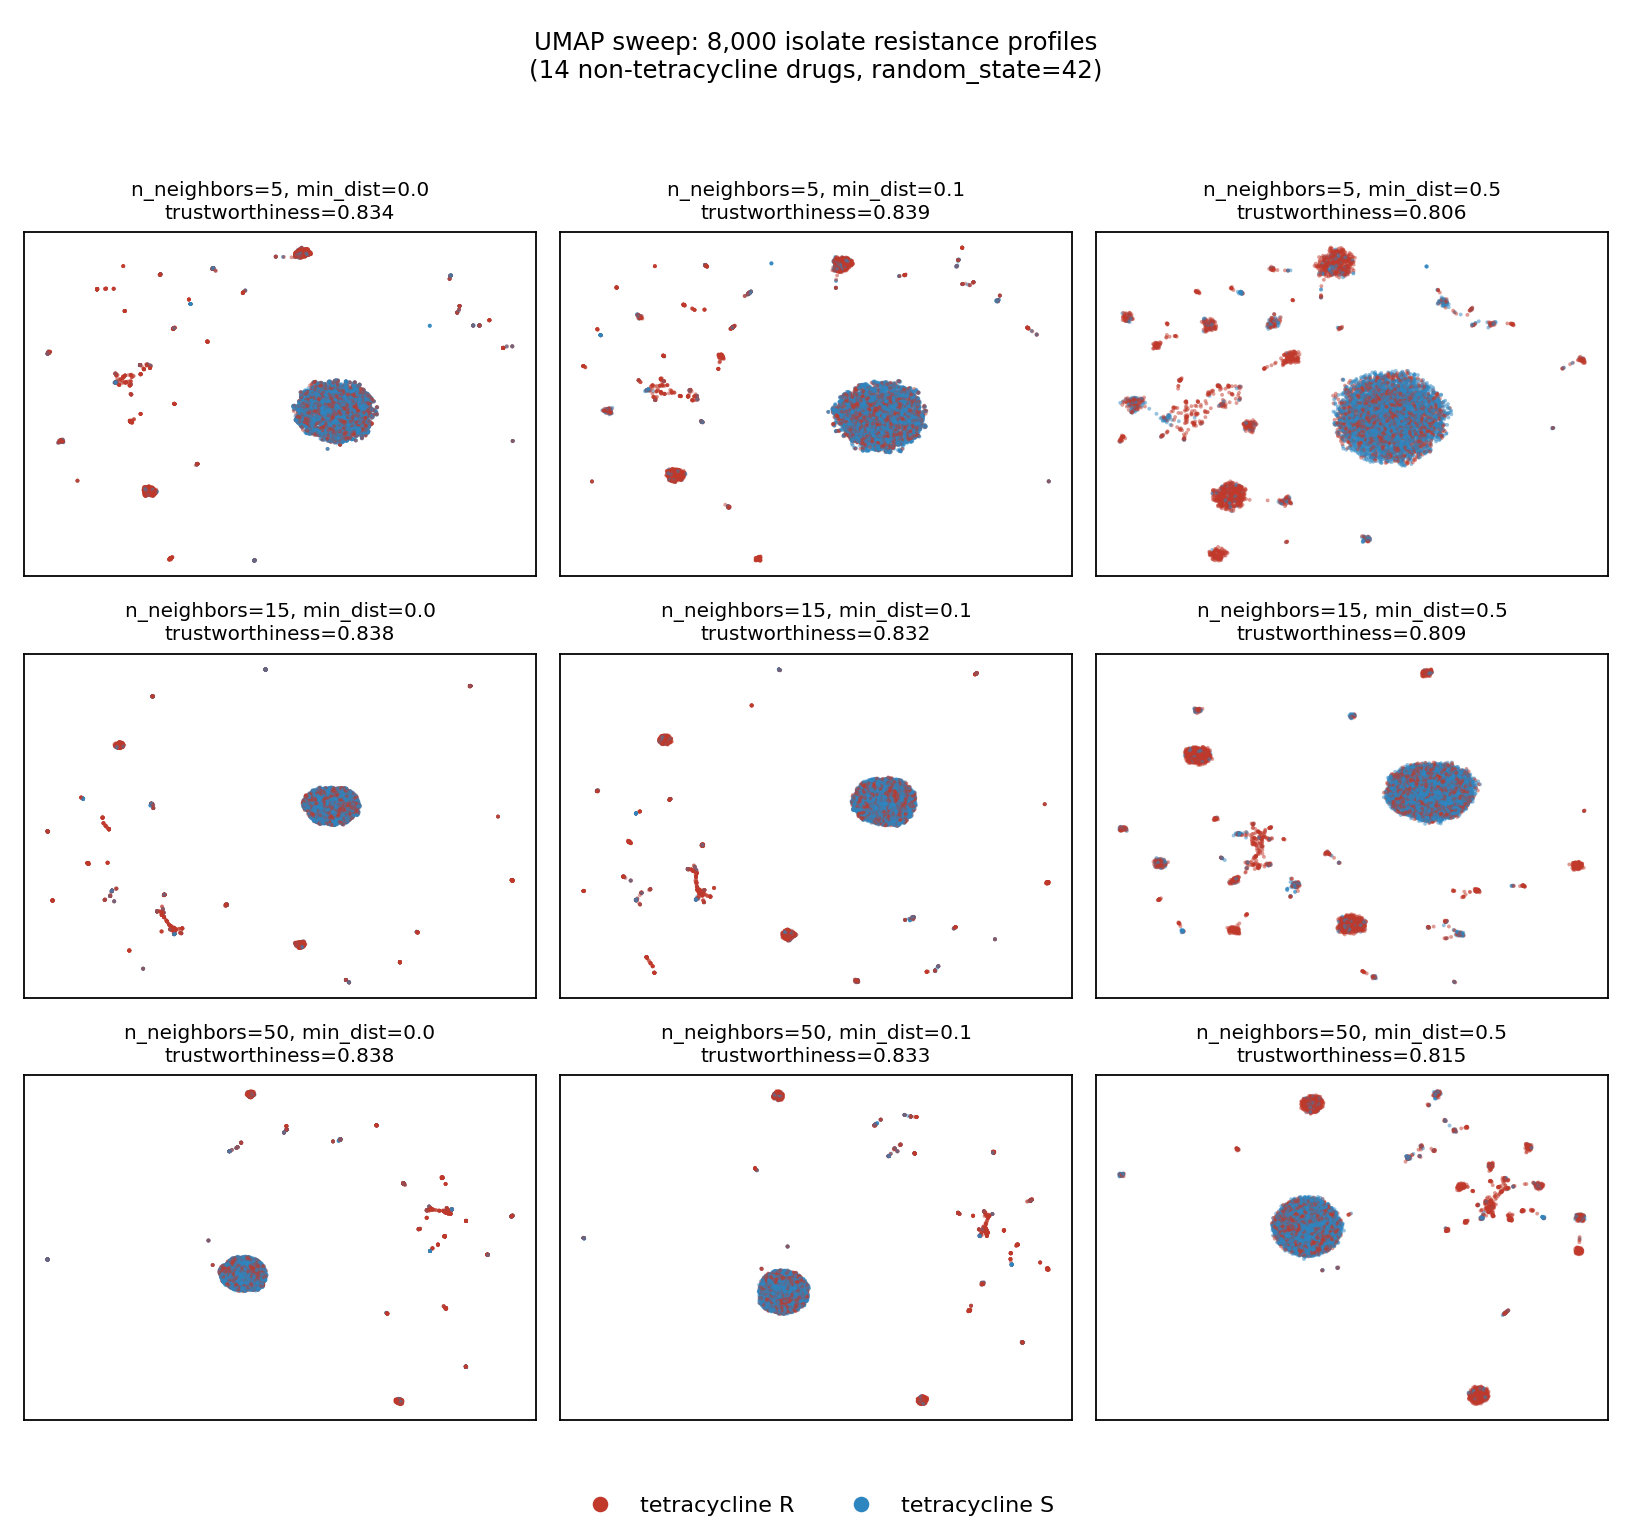

interim/fig3_coresistance.png


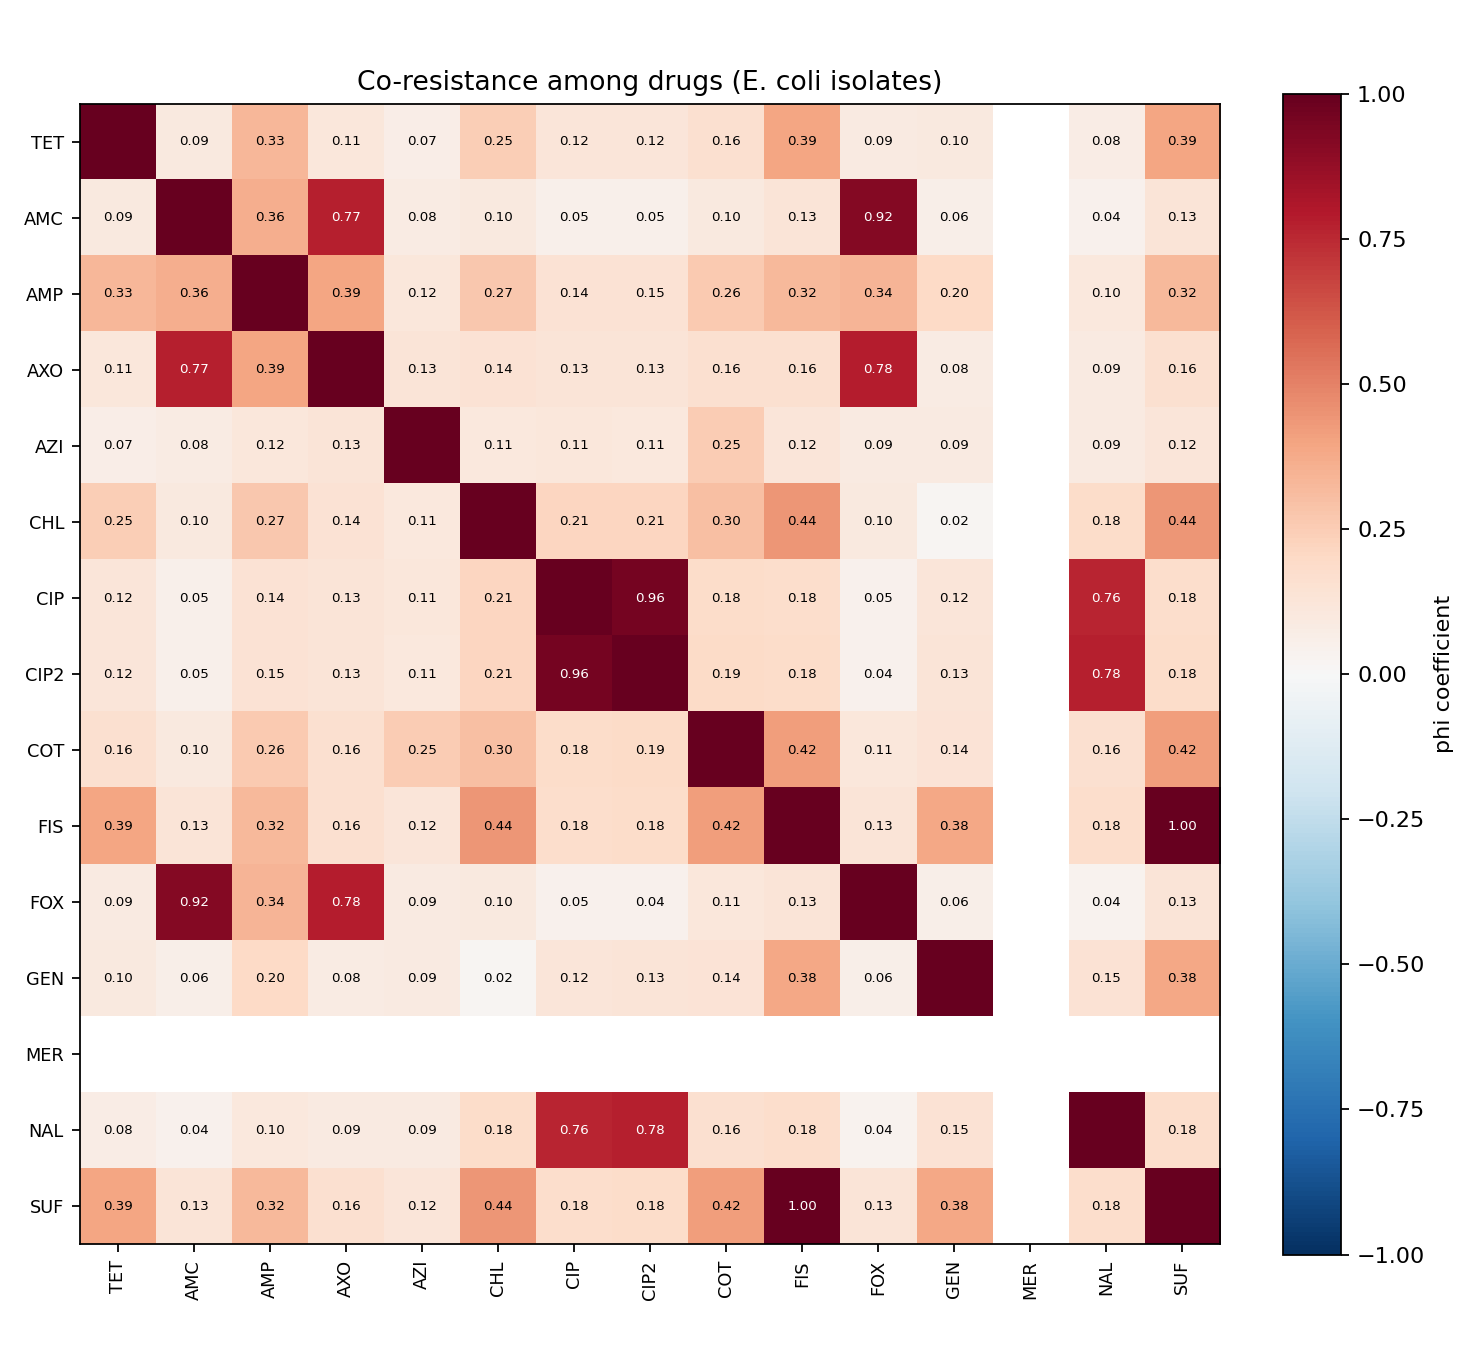

interim/fig4_missingness.png


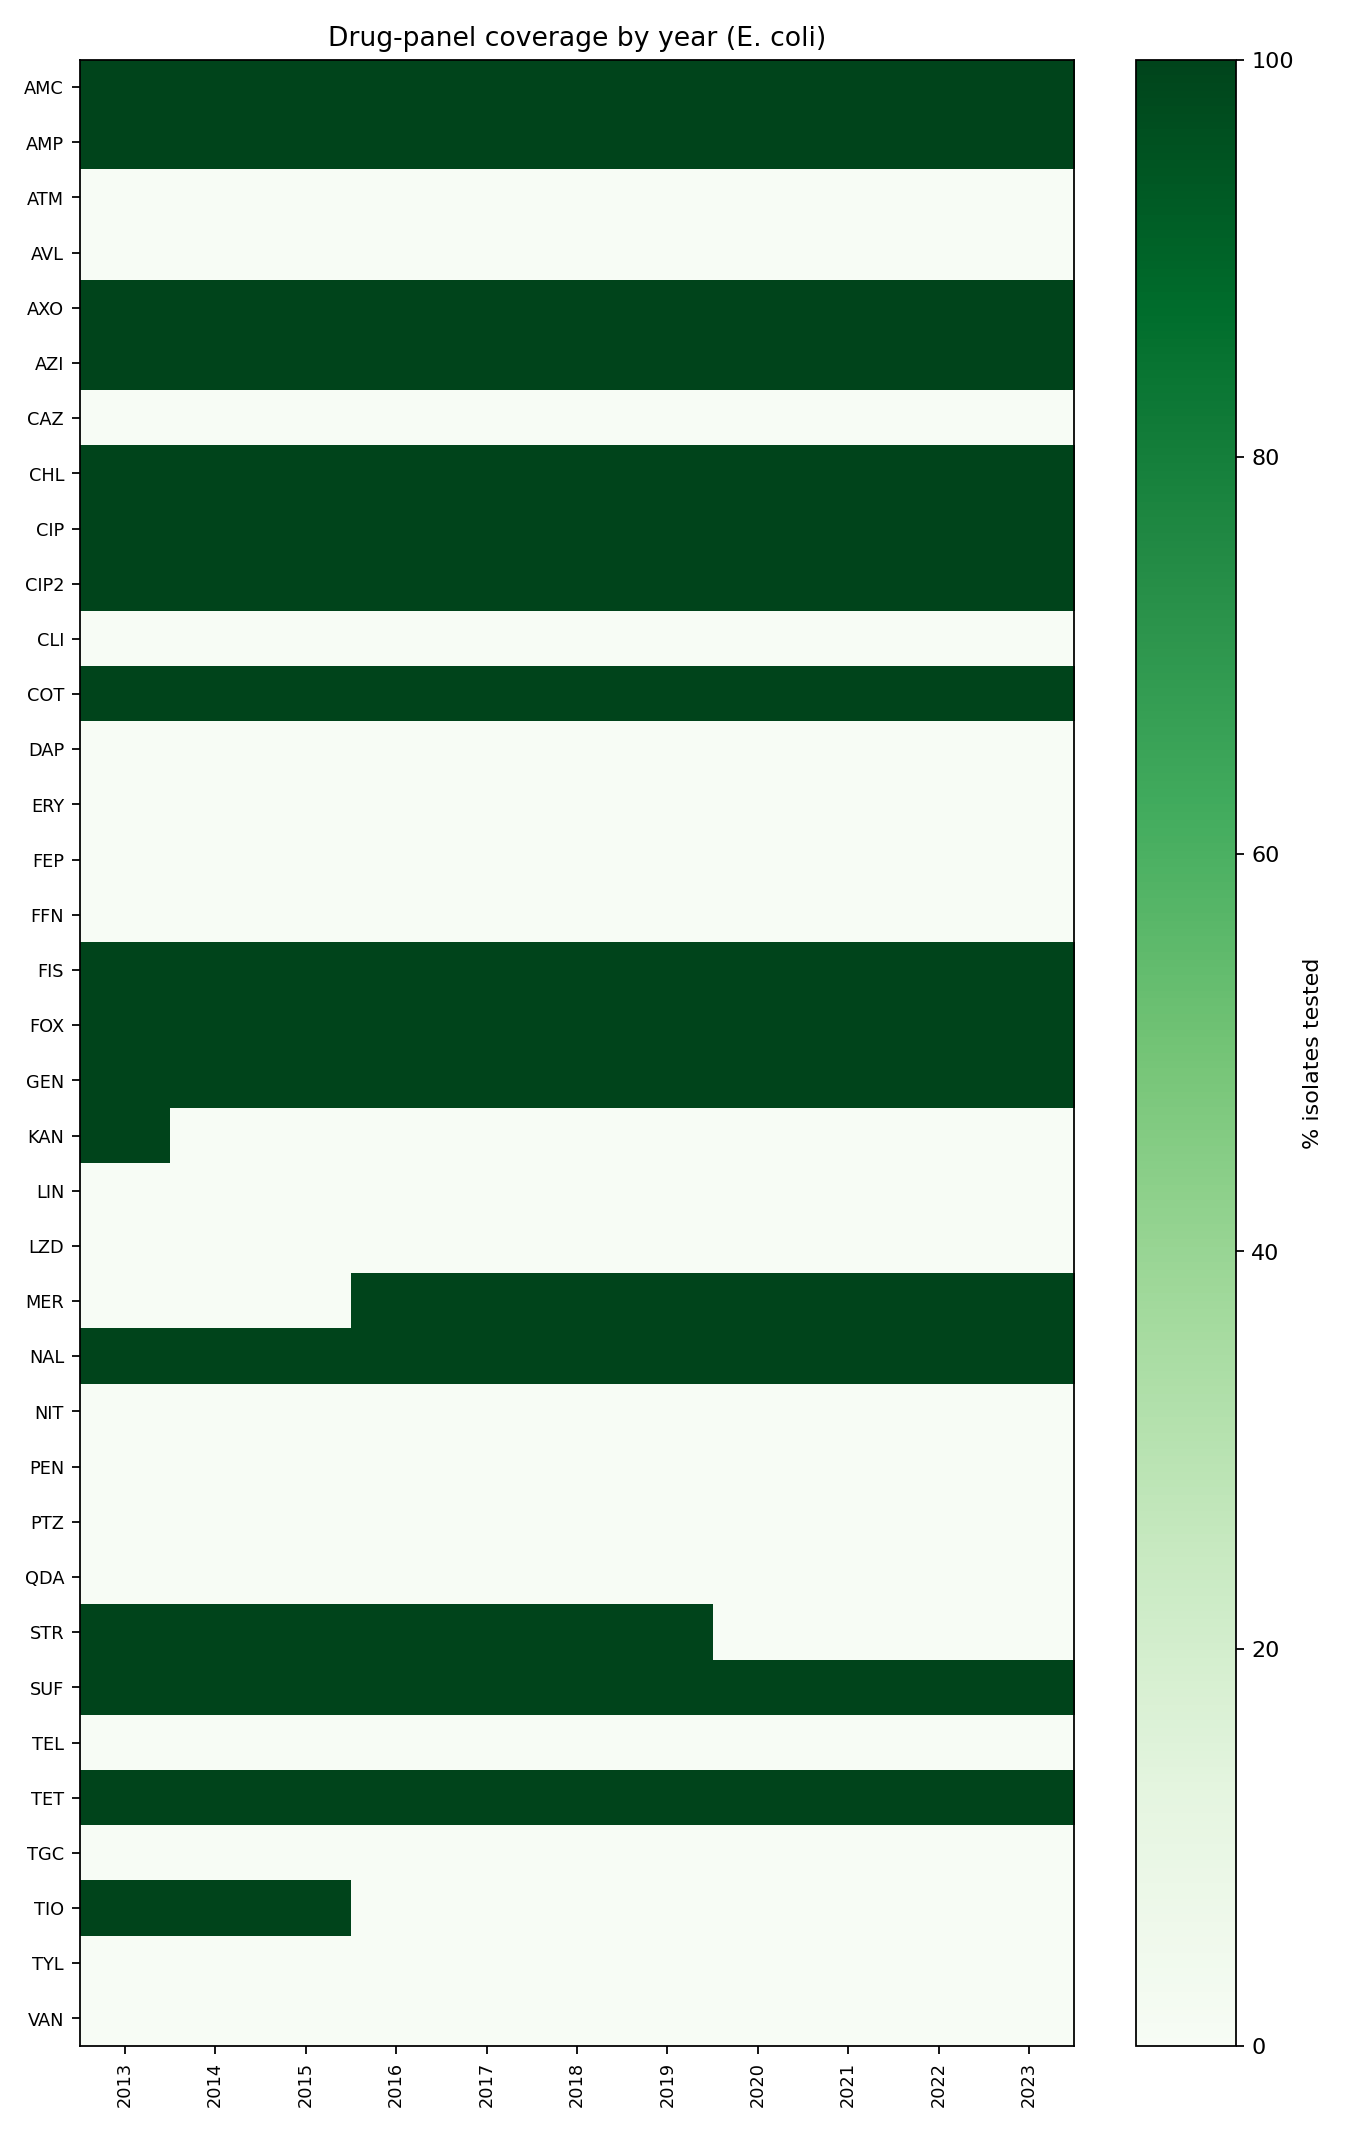

In [6]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('interim/fig*.png')):
    print(f); display(Image(f))

## Download the results

In [7]:
!rm -f interim_results.zip && zip -qr interim_results.zip interim
files.download('interim_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>